# Reglas interpretables de detección de bots con Programación Genética

Análisis del trabajo final de Computación Evolutiva (MAE-IA, UNI, 2026-II).

Este cuaderno no entrena nada: lee lo que dejó el pipeline en `results/` y en
`data/warehouse.duckdb`. Para regenerarlo todo:

```bash
make all           # datos, features, corrida base, corrida de un objetivo, métodos base y reporte
make sensitivity   # 45 corridas: un parámetro a la vez x 5 semillas
make ablation      # 20 corridas: con y sin eliminación de clones y mutación de crecimiento
make report        # tablas y figuras
make export RUN_ID=<corrida>   # regla final como modelo de dbt
```

Todos los datos son sintéticos: los genera un simulador basado en agentes. No
se usan datos de usuarios reales. Las frases con cifras se calculan en las
celdas de código, así que siempre corresponden a los resultados guardados.

In [1]:
import ast
import json
import sys
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from evo.data import FEATURES
from evo.report import final_rule, pick_main_run

FIG, TAB, RUNS = ROOT / "results/figures", ROOT / "results/tables", ROOT / "results/runs"
pd.options.display.float_format = "{:.4f}".format
pd.options.display.max_colwidth = 200

main_run = pick_main_run(RUNS)
cfg = yaml.safe_load((main_run / "config.yaml").read_text())
summary = json.loads((main_run / "summary.json").read_text())
rules = json.loads((main_run / "pareto.json").read_text())
EPS = cfg["fitness"]["fpr_max"]
con = duckdb.connect(str(ROOT / "data/warehouse.duckdb"), read_only=True)


def say(text):
    display(Markdown(text))


def pct(x, digits=1):
    return f"{100 * x:.{digits}f} %".replace(".", ",")


def num(x, digits=3):
    return f"{x:.{digits}f}".replace(".", ",")


def miles(n):
    return f"{int(n):,}".replace(",", " ")


print("Corrida principal:", main_run.name)

Corrida principal: 20261115-055801_multi_p200_g150_cx0.8_m0.3_h8_s42


## 1. Problema y datos (fase I)

Una plataforma social con chat y geolocalización recibe spam de cuentas
automatizadas. Se busca una **regla lógica legible** que marque, para cada
usuario y hora, si su actividad es de bot. Bloquear a un usuario real es
costoso, por lo que la regla debe cumplir `FPR ≤ 2 %`.

- **Variables de decisión:** la estructura de la regla (árbol de `AND`, `OR`,
  `NOT` y comparaciones) y sus umbrales, expresados como cuantiles de cada feature.
- **Objetivos:** maximizar los bots detectados (TPR), minimizar los usuarios
  reales marcados (FPR) y minimizar el tamaño de la regla.
- **Restricción:** `FPR ≤ ε = 0,02`, tratada por penalización.

El simulador genera cuatro tipos de agente. El **bot sigiloso** solo aparece en
el escenario de prueba: mide si la regla generaliza a un comportamiento que
nunca vio.

In [2]:
resumen = con.execute('''
    select scenario as escenario, agent_type as tipo, count(distinct user_id) as usuarios, count(*) as filas,
           avg(msgs_count) as msgs, avg(unique_recipients) as destinatarios, avg(link_ratio) as link_ratio,
           avg(dup_template_ratio) as dup_ratio, avg(reply_rate) as reply_rate,
           median(account_age_hours) as edad_h_mediana
    from fct_user_activity_hourly group by all order by 1 desc, 2
''').df()
display(resumen.style.format(precision=3).hide(axis="index"))
totales = con.execute("select scenario, count(*) n, avg(is_bot::int) bots from fct_user_activity_hourly group by 1").df().set_index("scenario")
say(f"Cada fila es un usuario en una hora con actividad. Entrenamiento: **{miles(totales.n['train'])}** filas "
    f"({pct(totales.bots['train'])} de bots). Prueba: **{miles(totales.n['test'])}** filas ({pct(totales.bots['test'])} de bots).")

escenario,tipo,usuarios,filas,msgs,destinatarios,link_ratio,dup_ratio,reply_rate,edad_h_mediana
train,adaptive_bot,240,1910,8.753,8.068,0.241,0.248,0.077,120.890
train,legit,3984,36864,4.775,2.712,0.021,0.013,0.643,2012.016
train,naive_bot,150,4283,44.123,40.414,0.700,0.941,0.010,47.645
test,adaptive_bot,124,918,8.830,8.168,0.249,0.254,0.074,132.267
test,legit,1991,18790,4.708,2.685,0.020,0.013,0.638,2075.589
test,naive_bot,75,2167,44.897,41.022,0.699,0.942,0.010,45.996
test,stealth_bot,144,930,6.489,5.649,0.083,0.066,0.193,337.961


Cada fila es un usuario en una hora con actividad. Entrenamiento: **43 057** filas (14,4 % de bots). Prueba: **22 805** filas (17,6 % de bots).

### ¿Basta una sola variable?

Si una comparación sola resolviera el problema no habría nada que evolucionar.
La tabla muestra, para cada feature, la mejor comparación `feature > umbral` o
`feature < umbral` que cumple `FPR ≤ 2 %` en entrenamiento.

In [3]:
train = con.execute("select * from fct_user_activity_hourly where scenario = 'train'").df()
y = train.is_bot.to_numpy()
filas = []
for f in FEATURES:
    x, mejor = train[f].to_numpy(), None
    for q in np.round(np.arange(0.01, 1.0, 0.01), 2):
        t = np.quantile(x, q)
        for op, mask in ((">", x > t), ("<", x < t)):
            tpr, fpr = mask[y].mean(), mask[~y].mean()
            if fpr <= EPS and (mejor is None or tpr > mejor["TPR"]):
                mejor = {"feature": f, "comparación": f"{f} {op} {t:.4g}", "TPR": tpr, "FPR": fpr}
    filas.append(mejor or {"feature": f, "comparación": "ninguna cumple la restricción", "TPR": 0.0, "FPR": np.nan})
una = pd.DataFrame(filas).sort_values("TPR", ascending=False)
display(una.style.format({"TPR": "{:.3f}", "FPR": "{:.4f}"}).hide(axis="index"))
top = una.iloc[0]
repiten = con.execute("select avg((dup_template_ratio > 0)::int) from fct_user_activity_hourly where scenario = 'train' and agent_type = 'legit'").fetchone()[0]
say(f"La mejor comparación de una sola variable (`{top['comparación']}`) detecta el **{pct(top.TPR)}** de las filas de bots. "
    f"Queda margen para reglas compuestas. Los usuarios reales también repiten mensajes: el {pct(repiten)} de sus filas tiene "
    f"`dup_template_ratio > 0`.")

feature,comparación,TPR,FPR
dup_template_ratio,dup_template_ratio > 0.2,0.877,0.0152
unique_recipients,unique_recipients > 7,0.852,0.0058
link_ratio,link_ratio > 0.25,0.820,0.0187
account_age_hours,account_age_hours < 81.49,0.735,0.0166
msgs_count,msgs_count > 13,0.706,0.0158
msgs_per_min,msgs_per_min > 0.2167,0.706,0.0158
avg_msg_len,avg_msg_len > 97,0.241,0.0179
max_geo_speed_kmh,max_geo_speed_kmh > 15.23,0.175,0.0174
reply_rate,reply_rate < 0,0.000,0.0000


La mejor comparación de una sola variable (`dup_template_ratio > 0.2`) detecta el **87,7 %** de las filas de bots. Queda margen para reglas compuestas. Los usuarios reales también repiten mensajes: el 8,2 % de sus filas tiene `dup_template_ratio > 0`.

**Lección de la primera versión del simulador.** En la primera corrida los
usuarios reales nunca repetían un mensaje, y la regla `dup_template_ratio > 0`
detectaba el 95,8 % de los bots con cero falsos positivos. El algoritmo "ganaba"
en la generación 0 y las 45 corridas del estudio de sensibilidad daban el mismo
resultado. Se corrigió agregando frases comunes ("hola", "ok") que comparten
todos los usuarios (`openspec/changes/fix-degenerate-first-run`). Es el riesgo
que ya anotaba el diseño del simulador: una regla puede limitarse a
"descubrir" lo que el modelador programó.

## 2. Diseño del algoritmo (fase II)

- **Paradigma:** Programación Genética tipada. Los tipos (`bool`, `Feature`,
  `Quantile`) garantizan que toda regla generada, cruzada o mutada sea válida.
- **Umbrales como cuantiles:** `gt(f, 0.9)` significa "la feature `f` supera su
  percentil 90 en entrenamiento". Un mismo umbral sirve para cualquier feature
  y siempre cae en el rango observado.
- **Selección:** NSGA-II con reemplazo (μ+λ) y un individuo por vector de
  objetivos (sin clones).
- **Operadores:** cruce de subárboles del mismo tipo y cuatro mutaciones
  (subárbol nuevo, cambio de nodo, cambio de umbral y crecimiento
  `x → and_(x, nuevo)` / `or_(x, nuevo)`). Límite estático de altura contra el bloat.
- **Restricción:** si `FPR > ε`, el objetivo de detección pasa a `TPR − λ·(FPR − ε)`.
- **Regla final:** la de mayor TPR en entrenamiento que cumple la restricción en
  entrenamiento y tiene a lo sumo 15 nodos. El escenario de prueba no interviene.

In [4]:
a, f = cfg["algorithm"], cfg["fitness"]
params = pd.DataFrame([
    ("Población (μ)", a["population"]), ("Generaciones", a["generations"]),
    ("Prob. de cruce", a["cxpb"]), ("Prob. de mutación", a["mutpb"]),
    ("Pesos de mutación", ", ".join(f"{k} {v}" for k, v in a["mutation_weights"].items())),
    ("Altura máxima", a["max_height"]), ("Profundidad inicial", f"{a['init_min_depth']}–{a['init_max_depth']} (half-and-half)"),
    ("Restricción", f"FPR ≤ {f['fpr_max']}, λ = {f['penalty_lambda']}"),
    ("Tamaño de referencia del hipervolumen", f["hv_ref_size"]),
    ("Máximo de nodos de la regla final", cfg["selection"]["max_size"]),
    ("Filas de entrenamiento", summary["n_train_rows"]), ("Semilla", cfg["seed"]),
], columns=["Parámetro", "Valor"])
display(params.style.hide(axis="index"))

Parámetro,Valor
Población (μ),200
Generaciones,150
Prob. de cruce,0.800000
Prob. de mutación,0.300000
Pesos de mutación,"uniform 0.3, node_replacement 0.2, ephemeral 0.25, extend 0.25"
Altura máxima,8
Profundidad inicial,1–4 (half-and-half)
Restricción,"FPR ≤ 0.02, λ = 5.0"
Tamaño de referencia del hipervolumen,511
Máximo de nodos de la regla final,15


## 3. Experimentación (fase III)

### 3.1 Convergencia

Curvas de la configuración base: la corrida principal más las 5 semillas del
estudio de sensibilidad con los mismos parámetros. La banda es ±1 desviación
estándar entre semillas.

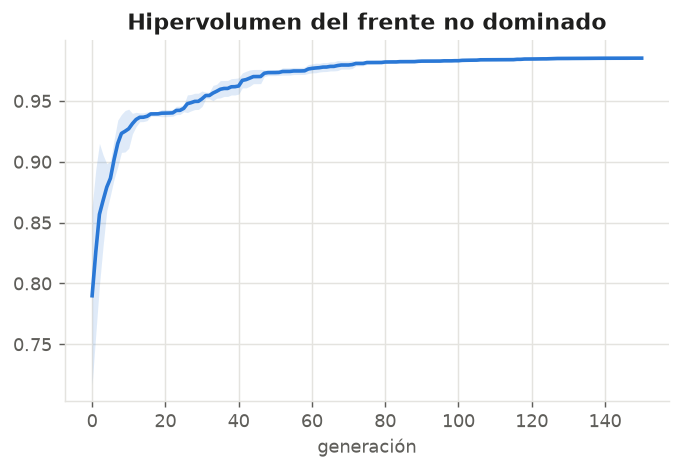

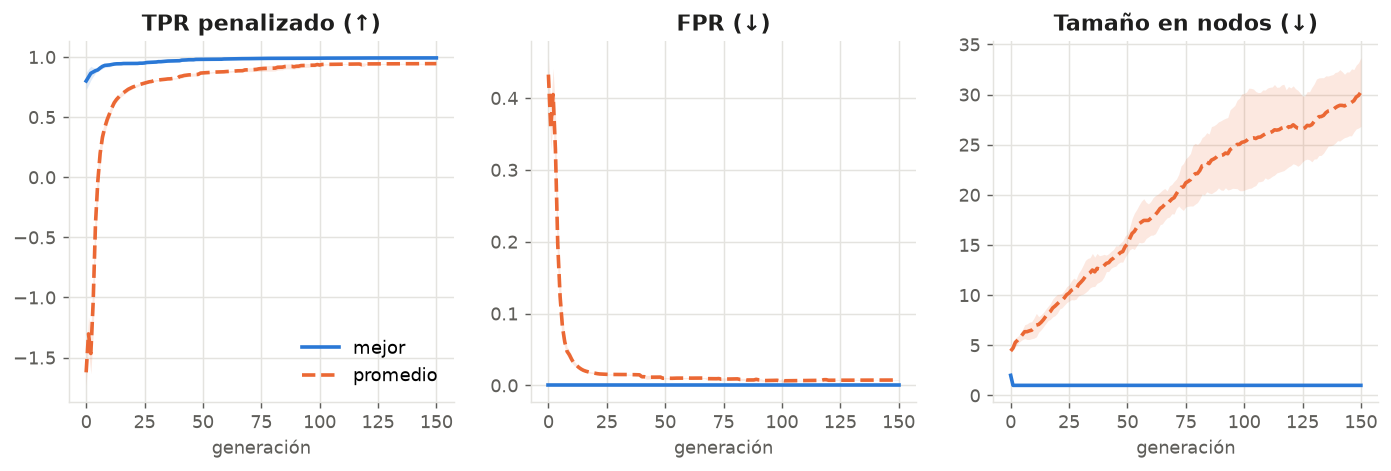

In [5]:
display(Image(str(FIG / "02_hipervolumen.png"), width=520))
display(Image(str(FIG / "01_convergencia.png"), width=980))

In [6]:
def misma_config(run):
    c = yaml.safe_load((run / "config.yaml").read_text())
    return all(c.get(k) == cfg.get(k) for k in ("algorithm", "fitness", "data"))

corridas = {}
for s in sorted(RUNS.rglob("summary.json")):
    if misma_config(s.parent):
        corridas[yaml.safe_load((s.parent / "config.yaml").read_text())["seed"]] = s.parent
logs = {seed: pd.read_csv(r / "logbook.csv") for seed, r in corridas.items()}
gens = [g for g in (0, 10, 25, 50, 75, 100, 125, 150) if g <= a["generations"]]
hv = pd.DataFrame({seed: lg.set_index("gen").hypervolume.loc[gens] for seed, lg in logs.items()})
tabla = pd.DataFrame({"hipervolumen (media)": hv.mean(axis=1), "desv.": hv.std(axis=1),
                      "nodos promedio": pd.DataFrame({s: lg.set_index("gen").size_avg.loc[gens] for s, lg in logs.items()}).mean(axis=1),
                      "vectores distintos": pd.DataFrame({s: lg.set_index("gen").n_unique.loc[gens] for s, lg in logs.items()}).mean(axis=1)})
tabla.index.name = "generación"
display(tabla.style.format({"hipervolumen (media)": "{:.4f}", "desv.": "{:.4f}", "nodos promedio": "{:.1f}", "vectores distintos": "{:.0f}"}))
g_fin = gens[-1]
ganancia = hv.mean(axis=1)
mitad = next(g for g in gens if ganancia[g] - ganancia[0] >= 0.9 * (ganancia[g_fin] - ganancia[0]))
say(f"Con {len(logs)} semillas, el hipervolumen sube de **{num(ganancia[0])}** a **{num(ganancia[g_fin])}**. "
    f"El 90 % de esa mejora ya está en la generación {mitad}; en las últimas 25 generaciones la media cambia "
    f"{num(ganancia[g_fin] - ganancia[gens[-2]], 4)}. La dispersión entre semillas baja de {num(hv.std(axis=1)[0])} a "
    f"{num(hv.std(axis=1)[g_fin], 4)}: semillas distintas llegan a frentes de calidad parecida. "
    f"El tamaño promedio de las reglas crece durante toda la corrida (de {num(tabla['nodos promedio'][0], 1)} a "
    f"{num(tabla['nodos promedio'][g_fin], 1)} nodos): el frente se extiende hacia reglas más grandes que ganan poco TPR.")

,hipervolumen (media),desv.,nodos promedio,vectores distintos
generación,,,,
0,0.7898,0.0798,4.4,92
10,0.9271,0.0176,6.7,200
25,0.9439,0.0030,10.2,200
50,0.9733,0.0027,15.1,200
75,0.9816,0.0017,21.2,200
100,0.9831,0.0007,25.3,200
125,0.9847,0.0012,26.6,200
150,0.9852,0.0012,30.2,200


Con 6 semillas, el hipervolumen sube de **0,790** a **0,985**. El 90 % de esa mejora ya está en la generación 50; en las últimas 25 generaciones la media cambia 0,0004. La dispersión entre semillas baja de 0,080 a 0,0012: semillas distintas llegan a frentes de calidad parecida. El tamaño promedio de las reglas crece durante toda la corrida (de 4,4 a 30,2 nodos): el frente se extiende hacia reglas más grandes que ganan poco TPR.

Las curvas "mejor FPR" y "mejor tamaño" son planas porque sus extremos son
triviales (la regla `FALSE` tiene FPR = 0 y un nodo). En un problema
multiobjetivo el indicador de convergencia es el hipervolumen, no el mejor
valor de un objetivo aislado.

### 3.2 Por qué hicieron falta dos mecanismos más (ablación)

Con el diseño inicial el algoritmo se estancaba: los clones de los pocos
puntos no dominados ocupaban las 200 plazas de la población, y ningún operador
podía agregar una condición a una regla que ya funcionaba. `make
ablation` compara las cuatro combinaciones con 5 semillas cada una.

In [7]:
abl = pd.read_csv(TAB / "ablation.csv")
abl["variante"] = abl.apply(lambda r: ("sin clones" if r["algorithm.dedupe"] else "con clones") + " · " +
                            ("con crecimiento" if r["algorithm.mutation_weights.extend"] > 0 else "sin crecimiento"), axis=1)
cols = {"variante": "variante", "hv_mean": "hipervolumen", "hv_std": "desv.", "tpr_final_test_mean": "TPR prueba (regla final)",
        "tpr_final_test_std": "desv. ", "size_final_mean": "nodos regla final", "runtime_mean": "segundos"}
display(abl[list(cols)].rename(columns=cols).style.format(precision=3).hide(axis="index"))
orig = abl[(~abl["algorithm.dedupe"]) & (abl["algorithm.mutation_weights.extend"] == 0)].iloc[0]
full = abl[(abl["algorithm.dedupe"]) & (abl["algorithm.mutation_weights.extend"] > 0)].iloc[0]
otros = abl[abl.index.isin([orig.name, full.name]) == False]
say(f"El algoritmo original se queda en hipervolumen **{num(orig.hv_mean)}** (± {num(orig.hv_std)}) y su regla final "
    f"detecta el {pct(orig.tpr_final_test_mean)} en prueba. Con cualquiera de los dos mecanismos el hipervolumen sube a "
    f"{num(otros.hv_mean.min())}–{num(max(otros.hv_mean.max(), full.hv_mean))}. Con los dos juntos la regla final llega a "
    f"**{pct(full.tpr_final_test_mean)}** (± {pct(full.tpr_final_test_std)}). La diferencia entre las tres variantes "
    f"corregidas es del orden de la dispersión entre semillas: lo que el experimento demuestra es que hace falta "
    f"**al menos uno** de los dos mecanismos, no que los dos juntos sean mejores que uno solo.")

variante,hipervolumen,desv.,TPR prueba (regla final),desv.,nodos regla final,segundos
con clones · sin crecimiento,0.880,0.002,0.697,0.000,3.000,1.382
con clones · con crecimiento,0.983,0.001,0.845,0.006,13.400,3.088
sin clones · sin crecimiento,0.985,0.001,0.839,0.006,13.000,6.952
sin clones · con crecimiento,0.985,0.001,0.848,0.020,15.000,7.348


El algoritmo original se queda en hipervolumen **0,880** (± 0,002) y su regla final detecta el 69,7 % en prueba. Con cualquiera de los dos mecanismos el hipervolumen sube a 0,983–0,985. Con los dos juntos la regla final llega a **84,8 %** (± 2,0 %). La diferencia entre las tres variantes corregidas es del orden de la dispersión entre semillas: lo que el experimento demuestra es que hace falta **al menos uno** de los dos mecanismos, no que los dos juntos sean mejores que uno solo.

### 3.3 Sensibilidad de parámetros

Diseño "uno a la vez": se varía un parámetro alrededor de la configuración base
y se repite con 5 semillas (9 configuraciones, 45 corridas).

population,mutpb,cxpb,max_height,hipervolumen,desv.,TPR prueba (regla final),desv.,TPR prueba (cota superior),segundos
100,0.3,0.8,8,0.9808,0.0026,0.840,0.007,0.879,2.4
200,0.1,0.8,8,0.9840,0.0010,0.857,0.015,0.881,7.1
200,0.3,0.6,8,0.9845,0.0007,0.844,0.003,0.886,6.5
200,0.3,0.8,6,0.9838,0.0008,0.843,0.007,0.880,7.0
200,0.3,0.8,8,0.9851,0.0013,0.848,0.020,0.883,7.5
200,0.3,0.8,10,0.9851,0.0008,0.846,0.015,0.880,7.2
200,0.3,0.95,8,0.9858,0.0011,0.853,0.013,0.886,7.8
200,0.5,0.8,8,0.9850,0.0007,0.852,0.017,0.892,7.9
400,0.3,0.8,8,0.9859,0.0010,0.849,0.007,0.883,24.5


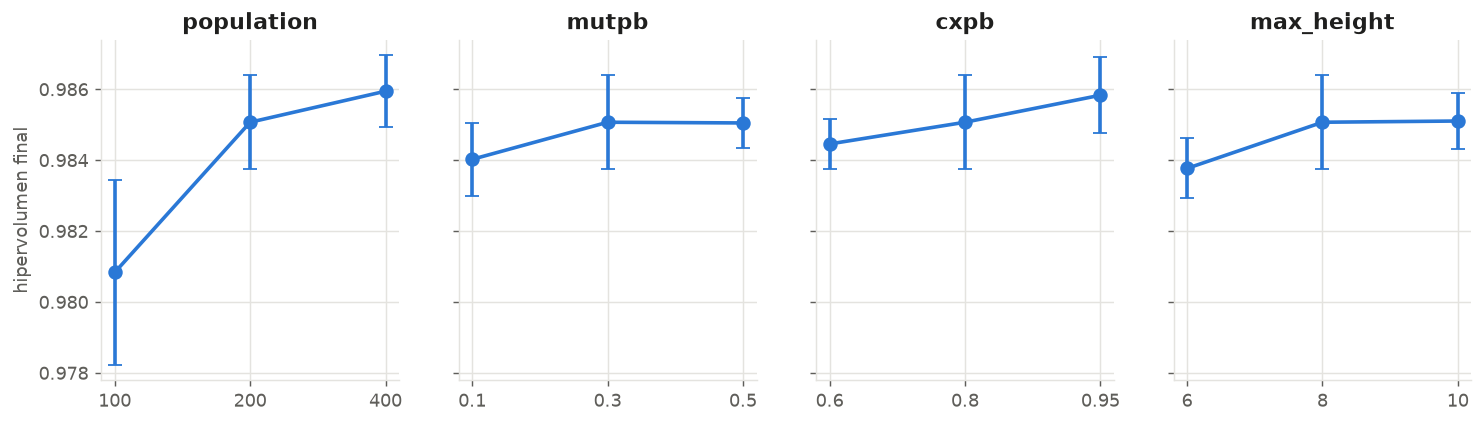

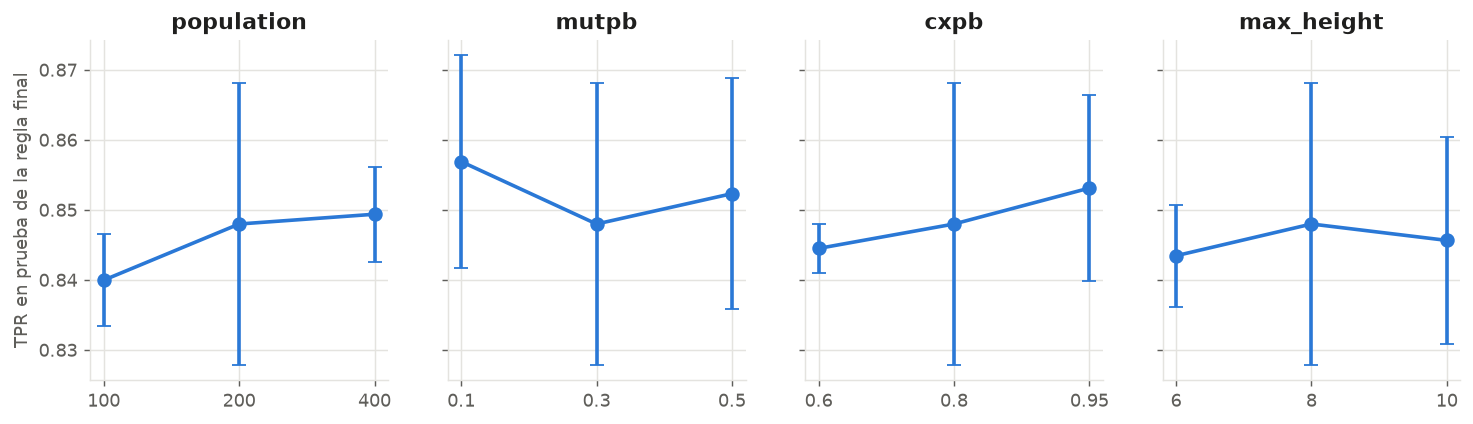

In [8]:
sens = pd.read_csv(TAB / "sensitivity.csv")
pcols = [c for c in sens.columns if c.startswith("algorithm.")]
base_vals = {c: sens[c].mode().iloc[0] for c in pcols}
vista = sens.rename(columns={c: c.split(".")[-1] for c in pcols})[
    [c.split(".")[-1] for c in pcols] + ["hv_mean", "hv_std", "tpr_final_test_mean", "tpr_final_test_std", "tpr_test_mean", "runtime_mean"]]
vista.columns = [c.split(".")[-1] for c in pcols] + ["hipervolumen", "desv.", "TPR prueba (regla final)", "desv. ", "TPR prueba (cota superior)", "segundos"]
display(vista.style.format({"hipervolumen": "{:.4f}", "desv.": "{:.4f}", "TPR prueba (regla final)": "{:.3f}", "desv. ": "{:.3f}",
                            "TPR prueba (cota superior)": "{:.3f}", "segundos": "{:.1f}", "mutpb": "{:g}", "cxpb": "{:g}"}).hide(axis="index"))
display(Image(str(FIG / "04_sensibilidad_hv.png"), width=980))
display(Image(str(FIG / "04b_sensibilidad_tpr.png"), width=980))

In [9]:
es_base = np.logical_and.reduce([sens[c] == v for c, v in base_vals.items()])
base_row = sens[es_base].iloc[0]
rango_hv = sens.hv_mean.max() - sens.hv_mean.min()
peor, mejor = sens.loc[sens.hv_mean.idxmin()], sens.loc[sens.hv_mean.idxmax()]


def describe(row):
    cambios = [f"{c.split('.')[-1]} = {row[c]:g}" for c in pcols if row[c] != base_vals[c]]
    return cambios[0] if cambios else "configuración base"


pop = sens[np.logical_and.reduce([sens[c] == v for c, v in base_vals.items() if c != "algorithm.population"])].sort_values("algorithm.population")
say(f"- El hipervolumen final varía poco entre configuraciones: de **{num(peor.hv_mean, 4)}** ({describe(peor)}) a "
    f"**{num(mejor.hv_mean, 4)}** ({describe(mejor)}), un rango de {num(rango_hv, 4)}. La desviación entre semillas de la "
    f"configuración base es {num(base_row.hv_std, 4)}.\n"
    f"- **Población:** es el parámetro con más efecto y más costo. De {pop['algorithm.population'].iloc[0]:g} a "
    f"{pop['algorithm.population'].iloc[-1]:g} individuos el hipervolumen pasa de {num(pop.hv_mean.iloc[0], 4)} a "
    f"{num(pop.hv_mean.iloc[-1], 4)} y el tiempo de {num(pop.runtime_mean.iloc[0], 1)} s a {num(pop.runtime_mean.iloc[-1], 1)} s.\n"
    f"- **TPR en prueba de la regla final:** entre {pct(sens.tpr_final_test_mean.min())} y {pct(sens.tpr_final_test_mean.max())}, "
    f"con desviaciones de hasta {pct(sens.tpr_final_test_std.max())}. Las diferencias entre configuraciones son menores que "
    f"el ruido entre semillas, así que no justifican preferir una configuración por esta métrica.")

- El hipervolumen final varía poco entre configuraciones: de **0,9808** (population = 100) a **0,9859** (population = 400), un rango de 0,0051. La desviación entre semillas de la configuración base es 0,0013.
- **Población:** es el parámetro con más efecto y más costo. De 100 a 400 individuos el hipervolumen pasa de 0,9808 a 0,9859 y el tiempo de 2,4 s a 24,5 s.
- **TPR en prueba de la regla final:** entre 84,0 % y 85,7 %, con desviaciones de hasta 2,0 %. Las diferencias entre configuraciones son menores que el ruido entre semillas, así que no justifican preferir una configuración por esta métrica.

Lectura: una vez corregido el estancamiento, el algoritmo es **poco sensible**
a las probabilidades de cruce y mutación y a la altura máxima dentro de los
rangos probados. La configuración base (población 200) es un compromiso
razonable entre calidad y tiempo.

La columna "cota superior" elige la regla mirando el escenario de prueba. Solo
se usa aquí, para comparar configuraciones; nunca para reportar la regla final.

## 4. Análisis de la solución (fase IV)

### 4.1 Frente de Pareto

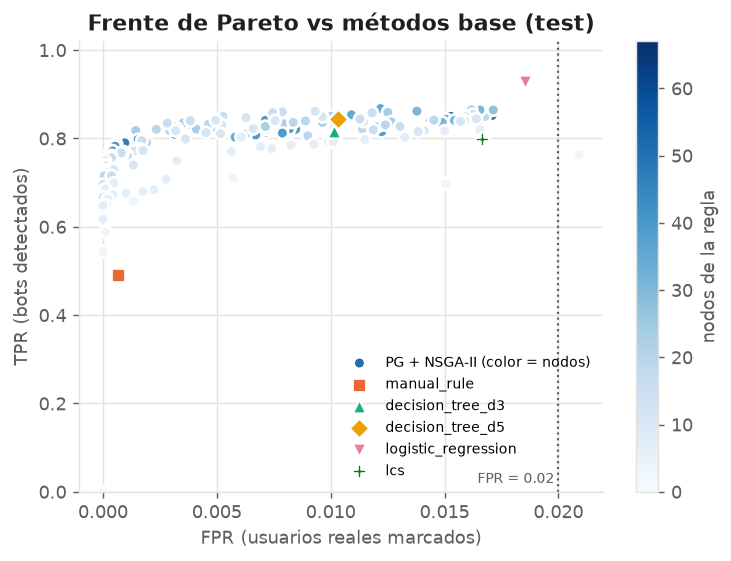

El frente de la corrida principal tiene **200 reglas** distintas, de 1 a 67 nodos; 199 cumplen `FPR ≤ 0.02` en entrenamiento. La figura las dibuja con sus métricas en **prueba**, por eso no forman una curva limpia: el frente se optimizó en entrenamiento.

In [10]:
display(Image(str(FIG / "03_pareto.png"), width=620))
fact = [r for r in rules if r["train"]["fpr"] <= EPS]
say(f"El frente de la corrida principal tiene **{len(rules)} reglas** distintas, de {min(r['size_simplified'] for r in rules)} a "
    f"{max(r['size_simplified'] for r in rules)} nodos; {len(fact)} cumplen `FPR ≤ {EPS}` en entrenamiento. "
    f"La figura las dibuja con sus métricas en **prueba**, por eso no forman una curva limpia: el frente se optimizó en entrenamiento.")

### 4.2 Regla final

In [11]:
best = final_rule(main_run)
say(f"```sql\n{best['sql_readable']}\n```")
met = pd.DataFrame({"entrenamiento": best["train"], "prueba": best["test"]}).T
met = met.rename(columns={"tpr": "TPR", "fpr": "FPR", "tpr_naive_bot": "TPR bot ingenuo",
                          "tpr_adaptive_bot": "TPR bot adaptativo", "tpr_stealth_bot": "TPR bot sigiloso"})
display(met.style.format("{:.4f}", na_rep="—"))
say(f"Regla `{best['rule_id']}`: **{best['size_simplified']} nodos**, features usadas: {', '.join('`' + f + '`' for f in best['features'])}.")
print("SQL exacto (el que se exporta a dbt):")
print(best["sql"])

```sql
((account_age_hours < 530.2) AND ((link_ratio > 0) OR (avg_msg_len > 30.35))) AND (reply_rate < 0.3333)
```

,TPR,FPR,TPR bot adaptativo,TPR bot ingenuo,TPR bot sigiloso
entrenamiento,0.9877,0.0195,0.9601,1.0000,—
prueba,0.8543,0.0162,0.9346,0.9995,0.4366


Regla `rule_24`: **15 nodos**, features usadas: `account_age_hours`, `avg_msg_len`, `link_ratio`, `reply_rate`.

SQL exacto (el que se exporta a dbt):
((account_age_hours < 530.2285111111114e0) AND ((link_ratio > 0.0) OR (avg_msg_len > 30.35424242424244e0))) AND (reply_rate < 0.3333333333333333e0)


**Lectura en lenguaje de negocio.** Cada comparación de la regla de arriba
corresponde a una de estas señales:

| Señal | Qué significa |
|---|---|
| `account_age_hours < umbral` | cuenta creada hace poco |
| `reply_rate < umbral` | casi nadie le responde |
| `dup_template_ratio > umbral` | repite el mismo mensaje dentro de la hora |
| `link_ratio > umbral` | una parte de sus mensajes lleva enlaces |
| `avg_msg_len > umbral` | mensajes largos (texto de plantilla, no saludos) |
| `unique_recipients > umbral` | escribe a muchas personas distintas en una hora |
| `msgs_count`, `msgs_per_min > umbral` | ritmo de envío alto |
| `max_geo_speed_kmh > umbral` | cambio de ubicación imposible |

Un moderador puede leer la regla, discutirla y ajustar un umbral sin volver a
entrenar nada. Esa es la ventaja frente a un modelo de puntaje.

### 4.3 Costo de la legibilidad

¿Cuánto se pierde por exigir una regla corta? Para cada presupuesto de nodos se
toma la regla de mayor TPR en entrenamiento que cumple la restricción.

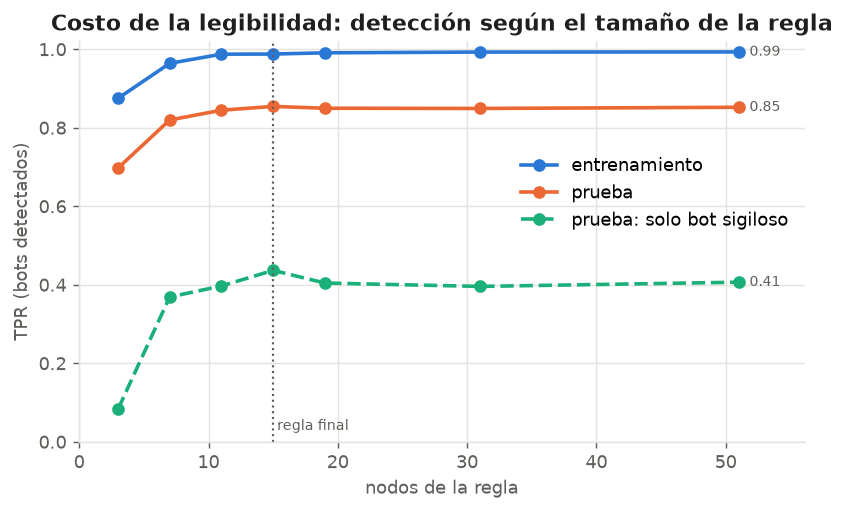

nodos,TPR train,FPR train,TPR prueba,FPR prueba,TPR sigiloso,regla
3,0.875,0.015,0.697,0.015,0.083,dup_template_ratio > 0.2
7,0.964,0.020,0.820,0.017,0.369,(account_age_hours < 413.9) AND (reply_rate < 0.25)
11,0.987,0.019,0.845,0.016,0.397,((account_age_hours < 530.2) AND (reply_rate < 0.3333)) AND (avg_msg_len > 29)
15,0.988,0.020,0.854,0.016,0.437,((account_age_hours < 530.2) AND ((link_ratio > 0) OR (avg_msg_len > 30.35))) AND (reply_rate < 0.3333)
19,0.991,0.020,0.850,0.017,0.404,((account_age_hours < 530.2) AND (avg_msg_len > 30.35)) AND (((link_ratio > 0) OR (reply_rate < 0.3333)) AND (reply_rate < 0.5))
31,0.993,0.018,0.849,0.016,0.396,(((account_age_hours < 1046) AND (avg_msg_len > 29)) AND (account_age_hours < 530.2)) AND (((link_ratio > 0) OR (reply_rate < 0.3333)) AND (((link_ratio > 0.2) OR (reply_rate < 0.25)) OR (dup_template_ratio > 0)))
51,0.993,0.019,0.852,0.017,0.406,(((account_age_hours < 1046) AND (avg_msg_len > 29)) AND (account_age_hours < 530.2)) AND (((link_ratio > 0) OR ((((dup_template_ratio > 0.1667) OR (reply_rate < 0.25)) AND (account_age_hours < 1178)) OR ((reply_rate < 0.5) AND (dup_template_ratio > 0)))) AND (((link_ratio > 0.2) OR (reply_rate < 0.25)) OR ((reply_rate < 1) AND (dup_template_ratio > 0.08333))))


Pasar de 3 a 15 nodos sube el TPR en prueba de 69,7 % a 85,4 %. La regla más grande del frente que cumple la restricción (51 nodos) obtiene 85,2 % en prueba: los nodos adicionales mejoran el entrenamiento (98,8 % → 99,3 %) pero no mejoran la prueba.

In [12]:
display(Image(str(FIG / "06_costo_legibilidad.png"), width=640))
tr = pd.read_csv(TAB / "size_tradeoff.csv").drop_duplicates("rule_id")
display(tr[["size", "train_tpr", "train_fpr", "test_tpr", "test_fpr", "test_tpr_stealth_bot", "sql_readable"]]
        .rename(columns={"size": "nodos", "train_tpr": "TPR train", "train_fpr": "FPR train", "test_tpr": "TPR prueba",
                         "test_fpr": "FPR prueba", "test_tpr_stealth_bot": "TPR sigiloso", "sql_readable": "regla"})
        .style.format(precision=3).hide(axis="index"))
chica, final_, grande = tr.iloc[0], tr[tr.rule_id == best["rule_id"]].iloc[0], tr.iloc[-1]
say(f"Pasar de {chica['size']:.0f} a {final_['size']:.0f} nodos sube el TPR en prueba de {pct(chica.test_tpr)} a {pct(final_.test_tpr)}. "
    f"La regla más grande del frente que cumple la restricción ({grande['size']:.0f} nodos) obtiene {pct(grande.test_tpr)} en prueba: "
    f"los nodos adicionales mejoran el entrenamiento ({pct(final_.train_tpr)} → {pct(grande.train_tpr)}) pero "
    f"{'no' if grande.test_tpr <= final_.test_tpr + 0.005 else 'apenas'} mejoran la prueba.")

### 4.4 Comparación con métodos base

Todos los métodos se ajustan solo con entrenamiento y se evalúan con las mismas
métricas. `gp_nsga2` es la regla final; `gp_single` es la misma Programación
Genética con un solo objetivo (`TPR − 5·FPR − 0,002·nodos`).

,nodos / tamaño,TPR train,FPR train,TPR prueba,FPR prueba,TPR adaptativo (prueba),TPR sigiloso (prueba)
método,,,,,,,
gp_nsga2,15,0.987659,0.019505,0.854296,0.016232,0.934641,0.436559
gp_single,15,0.965062,0.002307,0.827148,0.001809,0.881264,0.373118
manual_rule,15,0.625065,0.000964,0.491407,0.000639,0.025054,0.000000
decision_tree_d3,15,0.970972,0.011037,0.816189,0.010165,0.870370,0.334409
decision_tree_d5,59,0.989571,0.010775,0.845081,0.010325,0.946623,0.383871
logistic_regression,10,0.998262,0.019973,0.927273,0.018520,0.995643,0.690323
lcs,39,0.931862,0.017286,0.797758,0.016658,0.805011,0.327957


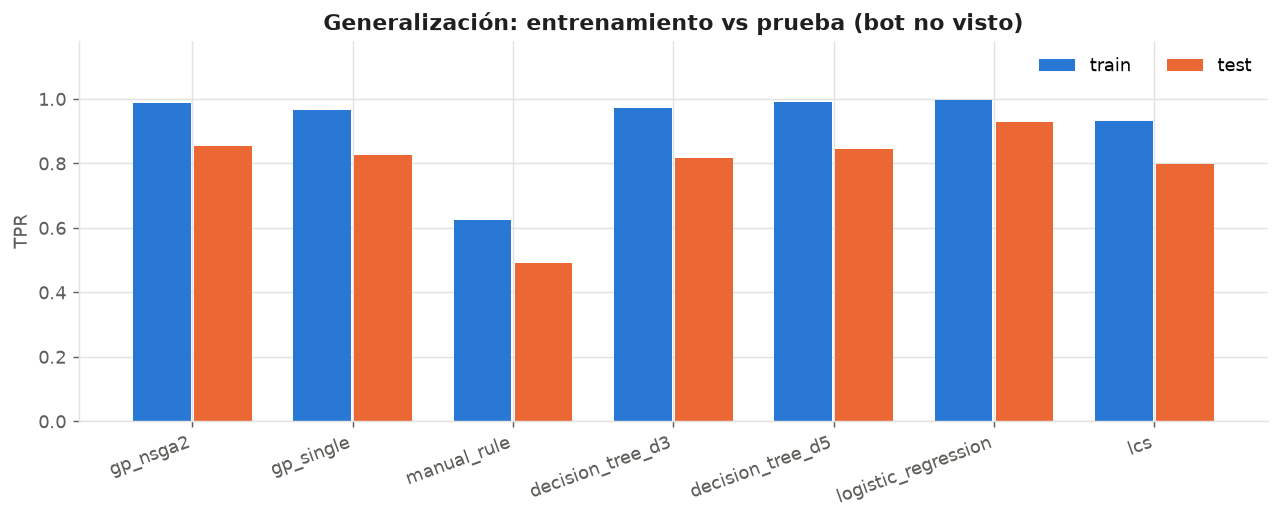

In [13]:
comp = pd.read_csv(TAB / "comparison.csv")
orden = list(dict.fromkeys(comp.method))
t = comp.pivot(index="method", columns="scenario", values=["tpr", "fpr"]).loc[orden]
tabla = pd.DataFrame({
    "nodos / tamaño": comp.drop_duplicates("method").set_index("method")["size"].loc[orden],
    "TPR train": t[("tpr", "train")], "FPR train": t[("fpr", "train")],
    "TPR prueba": t[("tpr", "test")], "FPR prueba": t[("fpr", "test")],
    "TPR adaptativo (prueba)": comp[comp.scenario == "test"].set_index("method").tpr_adaptive_bot.loc[orden],
    "TPR sigiloso (prueba)": comp[comp.scenario == "test"].set_index("method").tpr_stealth_bot.loc[orden],
})
tabla.index.name = "método"


def marca_fpr(v):
    return "font-weight: bold" if v > EPS else ""


display(tabla.style.format(precision=3).format({"nodos / tamaño": "{:.0f}"}).map(marca_fpr, subset=["FPR train", "FPR prueba"]))
display(Image(str(FIG / "05_train_vs_test.png"), width=900))

In [14]:
def compara(a, b, tol=0.01):
    return "iguala" if abs(a - b) < tol else ("supera" if a > b else "queda por debajo de")


m = tabla
gp, lr, d3, d5, single, lcs_, manual = (m.loc[k] for k in ("gp_nsga2", "logistic_regression", "decision_tree_d3",
                                                          "decision_tree_d5", "gp_single", "lcs", "manual_rule"))
viol = [k for k in m.index if m.loc[k, "FPR prueba"] > EPS]
say(f"- **Regla evolucionada (`gp_nsga2`, {gp['nodos / tamaño']:.0f} nodos):** TPR en prueba {pct(gp['TPR prueba'])} con FPR {pct(gp['FPR prueba'], 2)}.\n"
    f"- **Regresión logística:** es el método con más detección en prueba ({pct(lr['TPR prueba'])}; {pct(lr['TPR sigiloso (prueba)'])} del bot sigiloso "
    f"frente a {pct(gp['TPR sigiloso (prueba)'])} de la regla). Combina las 9 variables con pesos continuos; no es una regla que un moderador "
    f"pueda leer ni se traduce a un `WHERE` simple.\n"
    f"- **Árbol de decisión:** con profundidad 3 ({d3['nodos / tamaño']:.0f} nodos) obtiene {pct(d3['TPR prueba'])}; con profundidad 5 "
    f"({d5['nodos / tamaño']:.0f} nodos) {pct(d5['TPR prueba'])}. La regla evolucionada de {gp['nodos / tamaño']:.0f} nodos "
    f"{compara(gp['TPR prueba'], d5['TPR prueba'])} al árbol de profundidad 5, que tiene "
    f"{num(d5['nodos / tamaño'] / gp['nodos / tamaño'], 1)} veces más nodos, y "
    f"{compara(gp['TPR prueba'], d3['TPR prueba'])} al de profundidad 3.\n"
    f"- **PG de un objetivo:** {pct(single['TPR prueba'])} en prueba con FPR {pct(single['FPR prueba'], 2)}. Su aptitud fija de antemano cuánto "
    f"vale un falso positivo" + (", y termina en una regla más conservadora que la de NSGA-II: usa menos del margen de falsos positivos que "
    "permite la restricción y detecta menos." if single["FPR train"] < gp["FPR train"] and single["TPR prueba"] < gp["TPR prueba"] else ".") +
    f" NSGA-II entrega todo el frente y la elección se hace después.\n"
    f"- **LCS:** {pct(lcs_['TPR prueba'])} en prueba con {lcs_['nodos / tamaño']:.0f} condiciones repartidas en varias reglas con prioridad "
    f"(FPR en prueba {pct(lcs_['FPR prueba'], 2)}); no tiene un mecanismo para la restricción de FPR.\n"
    f"- **Regla manual:** {pct(manual['TPR prueba'])}. Atrapa al bot ingenuo y casi nada del adaptativo.\n"
    f"- **Restricción en prueba:** " + (f"superan `FPR ≤ {EPS}` en prueba: {', '.join('`' + v + '`' for v in viol)}." if viol else
                                       f"todos los métodos cumplen `FPR ≤ {EPS}` también en prueba."))

- **Regla evolucionada (`gp_nsga2`, 15 nodos):** TPR en prueba 85,4 % con FPR 1,62 %.
- **Regresión logística:** es el método con más detección en prueba (92,7 %; 69,0 % del bot sigiloso frente a 43,7 % de la regla). Combina las 9 variables con pesos continuos; no es una regla que un moderador pueda leer ni se traduce a un `WHERE` simple.
- **Árbol de decisión:** con profundidad 3 (15 nodos) obtiene 81,6 %; con profundidad 5 (59 nodos) 84,5 %. La regla evolucionada de 15 nodos iguala al árbol de profundidad 5, que tiene 3,9 veces más nodos, y supera al de profundidad 3.
- **PG de un objetivo:** 82,7 % en prueba con FPR 0,18 %. Su aptitud fija de antemano cuánto vale un falso positivo, y termina en una regla más conservadora que la de NSGA-II: usa menos del margen de falsos positivos que permite la restricción y detecta menos. NSGA-II entrega todo el frente y la elección se hace después.
- **LCS:** 79,8 % en prueba con 39 condiciones repartidas en varias reglas con prioridad (FPR en prueba 1,67 %); no tiene un mecanismo para la restricción de FPR.
- **Regla manual:** 49,1 %. Atrapa al bot ingenuo y casi nada del adaptativo.
- **Restricción en prueba:** todos los métodos cumplen `FPR ≤ 0.02` también en prueba.

### 4.5 Generalización al bot no visto

Todos los métodos pierden detección al pasar de entrenamiento a prueba, y casi
toda la pérdida viene del bot sigiloso, que se parece a un usuario real en
ritmo, enlaces y frases comunes. Es el resultado esperado y el más honesto del
trabajo: una regla aprendida de bots conocidos detecta bien las variantes de
esos bots y mal un comportamiento nuevo. En operación, esto obliga a vigilar el
TPR con casos confirmados y a volver a evolucionar las reglas cuando aparece un
patrón nuevo.

In [15]:
print("Reglas del LCS (de mayor a menor prioridad):")
print((TAB / "baseline_lcs_rules.txt").read_text())
print("Árbol de decisión de profundidad 3 como SQL:")
print((TAB / "baseline_tree_depth3.sql").read_text())

Reglas del LCS (de mayor a menor prioridad):
SI link_ratio <= 0 Y avg_msg_len > 16.5 Y avg_msg_len <= 80.5 Y max_geo_speed_kmh <= 0 -> real  (aptitud=39.12)
SI account_age_hours > 1560 Y max_geo_speed_kmh <= 0 -> real  (aptitud=15.70)
SI msgs_count > 5 Y msgs_per_min > 0.3 -> bot  (aptitud=14.70)
SI dup_template_ratio <= 0.5298 Y reply_rate > 0.6 -> real  (aptitud=14.30)
SI unique_recipients <= 3 Y avg_msg_len <= 80.5 -> real  (aptitud=10.90)
SI msgs_count > 1 Y reply_rate <= 0.6 Y account_age_hours > 1560 Y max_geo_speed_kmh > 0 -> real  (aptitud=10.50)
SI msgs_per_min <= 0.3 Y reply_rate <= 0 -> bot  (aptitud=10.30)
SI msgs_per_min > 0.01667 Y dup_template_ratio > 0 Y dup_template_ratio <= 0.5298 Y avg_msg_len <= 80.5 Y account_age_hours <= 1560 -> bot  (aptitud=10.12)
SI unique_recipients > 13 Y max_geo_speed_kmh <= 0 -> real  (aptitud=10.00)
SI unique_recipients > 3 Y link_ratio <= 0 Y avg_msg_len > 80.5 -> real  (aptitud=10.00)
SI link_ratio <= 0 Y avg_msg_len <= 80.5 Y max_geo_sp

### 4.6 La regla en producción: Python y SQL marcan las mismas filas

La regla final se exporta como modelo de dbt (`make export`). Esta celda
ejecuta el SQL exacto sobre la tabla de features y lo compara con las métricas
que calculó Python durante la evolución.

In [16]:
prueba = con.execute(f'''
    select count(*) filter (where is_bot) as bots, count(*) filter (where not is_bot) as reales,
           count(*) filter (where is_bot and ({best["sql"]})) as bots_marcados,
           count(*) filter (where not is_bot and ({best["sql"]})) as reales_marcados
    from fct_user_activity_hourly where scenario = 'test'
''').df().iloc[0]
tpr_sql, fpr_sql = prueba.bots_marcados / prueba.bots, prueba.reales_marcados / prueba.reales
print(f"SQL en DuckDB : TPR = {tpr_sql:.6f}  FPR = {fpr_sql:.6f}")
print(f"Python (numpy): TPR = {best['test']['tpr']:.6f}  FPR = {best['test']['fpr']:.6f}")
assert np.isclose(tpr_sql, best["test"]["tpr"]) and np.isclose(fpr_sql, best["test"]["fpr"]), "SQL y Python no coinciden"
modelo = f"flag_bots_{best['rule_id']}"
existe = con.execute("select count(*) from information_schema.tables where table_name = ?", [modelo]).fetchone()[0]
if existe:
    n_dbt = con.execute(f"select count(*) from {modelo} where scenario = 'test'").fetchone()[0]
    print(f"Modelo dbt {modelo}: {n_dbt} filas marcadas en prueba (esperadas: {int(prueba.bots_marcados + prueba.reales_marcados)})")
    assert n_dbt == prueba.bots_marcados + prueba.reales_marcados
else:
    print(f"El modelo dbt {modelo} todavía no existe: ejecuta make export RUN_ID={main_run.name}")

SQL en DuckDB : TPR = 0.854296  FPR = 0.016232
Python (numpy): TPR = 0.854296  FPR = 0.016232
Modelo dbt flag_bots_rule_24: 3735 filas marcadas en prueba (esperadas: 3735)


## 5. Conclusiones

1. **La Programación Genética tipada con NSGA-II encuentra reglas cortas y
   legibles** que cumplen la restricción de falsos positivos y detectan casi
   todos los bots conocidos. Frente a un árbol de decisión, llega a una
   detección parecida con una regla varias veces más pequeña.
2. **No es el método con más detección.** La regresión logística detecta más,
   sobre todo del bot no visto, a cambio de no ser una regla. La elección
   depende de cuánto vale poder leer, auditar y editar la regla.
3. **El multiobjetivo aporta el frente, no solo un punto.** Permite elegir
   después cuánta detección se cambia por legibilidad (sección 4.3). La versión
   de un objetivo obliga a fijar esos pesos antes de ver los resultados.
4. **La diversidad fue el problema central del diseño.** El diseño inicial, sin
   eliminación de clones ni operador de crecimiento, se estancaba en reglas de
   una sola comparación; cualquiera de los dos mecanismos lo evita (sección 3.2). Los parámetros clásicos (probabilidades de cruce
   y mutación, altura máxima) influyen mucho menos (sección 3.3).
5. **La generalización es limitada.** El bot sigiloso es el punto débil de
   todos los métodos. Ninguna regla aprendida solo de comportamiento conocido
   sustituye el monitoreo continuo.

### Limitaciones

- Los datos son simulados. Los parámetros del simulador (por ejemplo, cuánto
  repiten frases los usuarios reales) son supuestos razonables, no mediciones;
  la primera versión del simulador mostró cuánto pesan esos supuestos.
- La regla final se elige y se evalúa con una sola partición
  entrenamiento / prueba; la variación entre semillas del algoritmo sí está medida.
- El simplificador solo elimina constantes y dobles negaciones. Algunas reglas
  grandes del frente contienen condiciones redundantes (por ejemplo, dos
  umbrales sobre la misma variable), lo que infla su tamaño.
- El estudio de sensibilidad varía un parámetro a la vez: no mide interacciones.